# LLM setup



In [3]:
!pip uninstall -y datasets


Found existing installation: datasets 4.8.5
Uninstalling datasets-4.8.5:
  Successfully uninstalled datasets-4.8.5


In [1]:
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

IN_COLAB = "google.colab" in sys.modules


def installed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None

# Skipped once the packages are installed, so this cell can be re-run after restarting the session.
if IN_COLAB and installed_version("pandasai") != "3.0.0":
    if sys.version_info[:2] != (3, 11):
        raise RuntimeError("Choose a Python 3.11 Colab runtime before installing these packages.")
    # Install into the Python running these cells.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "uv>=0.8,<1"])
    # Same versions as uv.lock (torch is preinstalled on Colab).
    packages = [
        "ipython>=8,<9",
        "matplotlib-inline<0.2",
        "numpy==1.26.4",
        "pandas==2.3.3",
        "transformers==5.17.0",
        "accelerate==1.15.0",
        "bitsandbytes==0.50.2",
        "peft==0.21.2",
        "sentence-transformers==6.1.0",
        "requests",
        "pandasai==3.0.0",
    ]
    subprocess.check_call([sys.executable, "-m", "uv", "pip", "install",
                           "--python", sys.executable, *packages])
    print("Installation finished. Choose Runtime → Restart session before continuing.")

In [2]:
%pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 64.6 MB/s eta 0:00:00


## Get the project code from github

On Colab, clone your team's repository so that the `ift6758` package can be imported.
For a private repository, create a GitHub [personal access token](https://docs.github.com/en/authentication/keeping-your-account-and-data-secure/managing-your-personal-access-tokens) with read access and add it to Colab's *Secrets* (key icon in the left sidebar) as `GITHUB_TOKEN`. Never paste the token in the notebook.

In [3]:
import os
import subprocess
IN_COLAB=True
if IN_COLAB:
    from google.colab import userdata

    REPO = "aliciavaq/data_science_project"
    REPO_DIR = "/content/repo"
    if not os.path.exists(REPO_DIR):
        token = userdata.get("GITHUB_TOKEN")
        subprocess.check_call(["git", "clone", f"https://{token}@github.com/{REPO}.git", REPO_DIR])
    sys.path.insert(0, REPO_DIR)

In [ ]:
!git -C /content/repo pull

Already up to date.


## Check the GPU

In [4]:
import torch

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("No CUDA GPU found. On Colab, select a T4 GPU runtime (Runtime → Change runtime type).")

GPU: Tesla T4


In [5]:
import os
from google.colab import drive
drive.mount("/content/drive")
os.environ["HOCKEY_DATA_DIR"] = "/content/drive/MyDrive/nhl_data"

from ift6758.data import get_hockey_data
get_hockey_data(2020, os.environ["HOCKEY_DATA_DIR"])

Mounted at /content/drive
Retrieving NHL data for the 2020-21 season.
Number of games to process: 952
Processed 100/952 games
Processed 200/952 games
Processed 300/952 games
Processed 400/952 games
Processed 500/952 games
Processed 600/952 games
Processed 700/952 games
Processed 800/952 games
Processed 900/952 games
Processed 952/952 games


,eventId,timeInPeriod,timeRemaining,situationCode,homeTeamDefendingSide,typeCode,typeDescKey,sortOrder,periodDescriptor.number,periodDescriptor.periodType,...,details.discreteClip,details.typeCode,details.descKey,details.duration,details.committedByPlayerId,details.drawnByPlayerId,details.servedByPlayerId,game_id,details.goalInGame,periodDescriptor.otPeriods
0,51,00:00,20:00,1551,right,520,period-start,8,1,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020020001,NaN,NaN
1,52,00:00,20:00,1551,right,502,faceoff,9,1,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020020001,NaN,NaN
2,53,00:16,19:44,1551,right,506,shot-on-goal,10,1,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020020001,NaN,NaN
3,8,00:23,19:37,1551,right,525,takeaway,11,1,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020020001,NaN,NaN
4,54,00:28,19:32,1551,right,508,blocked-shot,12,1,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020020001,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287921,699,19:24,00:36,0651,left,506,shot-on-goal,748,3,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020030415,NaN,NaN
287922,700,19:33,00:27,0651,left,508,blocked-shot,749,3,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020030415,NaN,NaN
287923,776,19:40,00:20,0651,left,503,hit,750,3,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020030415,NaN,NaN
287924,777,20:00,00:00,0651,left,521,period-end,751,3,REG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020030415,NaN,NaN


# Load Tidied table from question 3 implementation

In [6]:
import json, re, difflib, operator
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ift6758.data.question_3 import create_shot_dataframe


#Here, we load seasons already, in cache, makes no sense to start downloading season now

import os, json, re, difflib, operator
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ift6758.data.question_3 import create_shot_dataframe

# Loads seasons that are already downloaded (no downloading here).
# Each season is read from disk once, then kept in _cache.
_cache = {}

def data_dir():
    return Path(os.environ["HOCKEY_DATA_DIR"])

def cached_seasons():
    #Return the start years of the seasons that have been downloaded
    seasons = []
    for f in data_dir().iterdir():
        if not (f.is_dir() and len(f.name) == 7 and f.name[:4].isdigit()):
            continue
        if len(list(f.glob("*.json"))) == 0:
            continue
        seasons.append(int(f.name[:4]))

    return sorted(seasons)

def load_season(year):
    if year not in _cache:
        df = create_shot_dataframe(year, data_dir())
        df["is_goal"] = df["event_type"].eq("goal")
        _cache[year] = df
    return _cache[year]

def load_multiple_seasons(years):
    return pd.concat([load_season(y) for y in years], ignore_index=True)

df = load_season(2020)
print(cached_seasons(), df.shape)
df.head()

[2020] (57734, 18)


,game_id,event_id,season,game_type,period,time,team,event_type,x,y,shooter,goalie,shot_type,is_empty_net,situation_code,strength_type,strength,is_goal
0,2020020001,53,2020-21,Regular season,1,00:16,PHI,shot-on-goal,-74,29,Travis Konecny,Tristan Jarry,wrist,None,1551,Even strength,5v5,False
1,2020020001,9,2020-21,Regular season,1,00:34,PIT,shot-on-goal,49,-25,Evan Rodrigues,Carter Hart,wrist,None,1551,Even strength,5v5,False
2,2020020001,55,2020-21,Regular season,1,01:05,PHI,shot-on-goal,-52,-31,Joel Farabee,Tristan Jarry,backhand,None,1551,Even strength,5v5,False
3,2020020001,62,2020-21,Regular season,1,02:51,PIT,shot-on-goal,43,39,Evan Rodrigues,Carter Hart,snap,None,1551,Even strength,5v5,False
4,2020020001,65,2020-21,Regular season,1,03:44,PHI,shot-on-goal,-53,8,Claude Giroux,Tristan Jarry,slap,None,1551,Even strength,5v5,False


# Query functions

These are the functions that actually compute the answers

In [9]:
OPERATORS = ["==", "!=", ">", ">=", "<", "<=", "in", "not in"]

def condition(df, column, op, value):
    # returns a True/False mask: which rows satisfy "column op value"
    col = df[column]

    if op == "==":
        return col ==value
    elif op == "!=":
        return col !=value
    elif op == ">":
        return col > value
    elif op == ">=":
        return col >=value
    elif op == "<":
        return col < value
    elif op == "<=":
        return col <= value
    elif op == "in":
        return col.isin(value)
    elif op == "not in":
        return ~col.isin(value)
    else:
        raise ValueError(f"unknown operator {op}")

# Filtering tool

def filter_rows(df, filters):
    # filters is a list. Example [{"column": "team", "op": "in", "value": ["MTL","TOR"]}]
    for f in filters or []:
        mask = condition(df, f["column"], f["op"], f["value"])
        df = df[mask]
    return df


def compute_total(df, metric):
    # counts total shots or total goals
    if metric == "shots":
        return len(df)
    if metric == "goals":
        return int(df["is_goal"].sum())
    raise ValueError(f"compute_total only counts shots or goals, not {metric}")

def grouping(df, group_by, metric):
    # one row per group with shots and goals, biggest first
    if metric not in ("shots", "goals"):
        raise ValueError(f"grouping only counts shots or goals, not {metric}")
    table = df.groupby(group_by)["is_goal"].agg(shots="size", goals="sum")
    return table.sort_values(metric, ascending=False)

# generic percentage function
def percentage(df, percent_of, group_by=None):
    # percent_of is one condition, e.g. {"column": "event_type", "op": "==", "value": "goal"}
    selected= condition(df, percent_of["column"], percent_of["op"], percent_of["value"])

    if group_by is None:
        if len(df) == 0:
            return float("nan")
        return round(100 * selected.mean(), 2)
    result = 100 * selected.groupby(df[group_by]).mean()
    return result.round(2).sort_values(ascending=False)

#

def plot_result(result, metric, group_by, season, plot_type="bar"):
    if isinstance(result, pd.DataFrame):
        result = result[metric]

    result.plot(kind=plot_type, figsize=(10, 5),
                title=f"{metric} by {group_by} ({season}-{str(season + 1)[-2:]})")
    plt.xlabel(group_by)
    plt.ylabel(metric)
    plt.tight_layout()
    plt.show()




## Allowed values

The lists of values Qwen is allowed to use.This is constant for the table

In [19]:
TEAMS = sorted(df["team"].dropna().unique())
SHOT_TYPES =sorted(df["shot_type"].dropna().unique())
GAME_TYPES =sorted(df["game_type"].dropna().unique())
EVENT_TYPES =sorted(df["event_type"].dropna().unique())
STRENGTH_TYPES =sorted(df["strength_type"].dropna().unique())
PERIODS = sorted(df["period"].dropna().unique())

# columns for filtering
ALLOWED_VALUES = {
    "team": TEAMS,
    "shot_type": SHOT_TYPES,
    "game_type": GAME_TYPES,
    "event_type": EVENT_TYPES,
    "strength_type": STRENGTH_TYPES,
    "period": PERIODS,
}
NUMERIC = ["period"]
GROUP_BY = ["team", "shot_type", "game_type", "strength_type", "period"]
METRICS = ["shots", "goals", "goal_pct", "percentage"]
PLOT_TYPES = ["bar", "barh", "line"]
GOAL = {"column": "event_type", "op": "==", "value": "goal"}

##Run Query
The metric decides which function does the work:
- `goal_pct` or `percentage`:`percentage`
- `shots` or `goals` with no grouping : `compute_total`
- `shots` or `goals` with a grouping : `grouping

In [12]:
def query(season, metric, filters=None, group_by=None, percent_of=None,
          plot=False, plot_type="bar"):
    # runs the steps in order: load -> filter -> compute -> (plot)
    if isinstance(group_by, list):
        group_by = group_by[0] if group_by else None
    df = load_season(season)
    df = filter_rows(df, filters)

    if metric == "goal_pct":
        result = percentage(df, GOAL, group_by)
    elif metric == "percentage":
        result = percentage(df, percent_of, group_by)
    elif group_by is None:
        result = compute_total(df, metric)
    else:
        result = grouping(df, group_by, metric)

    if plot:
        plot_result(result, metric, group_by, season, plot_type)

    return result

In [14]:
ALLOWED_KEYS = {"season", "metric", "filters", "group_by", "percent_of", "plot", "plot_type"}

def check_value(name, value, allowed):
    # value can be one value or a list of values
    values = value if isinstance(value, list) else [value]
    for v in values:
        if v not in allowed:
            raise ValueError(f"unknown {name} '{v}', choose from {list(allowed)}")


def check_condition(c):
    # c must look like {"column": ..., "op": ..., "value": ...}
    if not isinstance(c, dict) or set(c) != {"column", "op", "value"}:
        raise ValueError('each condition must be {"column": ..., "op": ..., "value": ...}')

    column, op, value = c["column"], c["op"], c["value"]

    if column not in ALLOWED_VALUES:
        raise ValueError(f"cannot use column '{column}', choose from {list(ALLOWED_VALUES)}")
    if op not in OPERATORS:
        raise ValueError(f"unknown operator '{op}', choose from {OPERATORS}")

    if op in (">", ">=", "<", "<="):
        if column not in NUMERIC:
            raise ValueError(f"'{op}' only works with {NUMERIC}")
        if not isinstance(value, (int, float)):
            raise ValueError(f"'{op}' needs a number")
        return

    if op in ("in", "not in") and not isinstance(value, list):
        raise ValueError(f"'{op}' needs a list, e.g. ['MTL', 'TOR']")

    check_value(column, value, ALLOWED_VALUES[column])


def validate(args):
    # checks Qwen's JSON before anything runs
    if not isinstance(args, dict):
        raise ValueError("reply must be one JSON object")

    unknown = set(args) - ALLOWED_KEYS
    if unknown:
        raise ValueError(f"unknown keys {sorted(unknown)}, allowed: {sorted(ALLOWED_KEYS)}")

    if "season" not in args or "metric" not in args:
        raise ValueError("season and metric are required")
    check_value("season", args["season"], cached_seasons())
    check_value("metric", args["metric"], METRICS)

    for f in args.get("filters") or []:
        check_condition(f)

    if args["metric"] == "percentage":
        if not args.get("percent_of"):
            raise ValueError("metric 'percentage' needs percent_of")
        check_condition(args["percent_of"])

    if args.get("group_by") is not None:
        check_value("group_by", args["group_by"], GROUP_BY)

    if args.get("plot"):
        if not args.get("group_by"):
            raise ValueError("a plot needs a group_by column")
        check_value("plot_type", args.get("plot_type", "bar"), PLOT_TYPES)

## Check Qwen's reply

Before running any code using JSON, `validate()` makes sure Qwen's JSON only runs what is allowed:

In [16]:
def require(ok, message):
    if not ok:
        raise ValueError(message)


def check_value(name, value, allowed):
    values = value if isinstance(value, list) else [value]
    for v in values:
        require(v in allowed, f"unknown {name} '{v}', choose from {list(allowed)}")

def check_condition(c):
    require(isinstance(c, dict) and set(c) == {"column", "op", "value"},
            'each condition must be {"column":...,"op": ...,"value":...}')
    column, op, value = c["column"], c["op"], c["value"]

    check_value("column", column, ALLOWED_VALUES)
    check_value("operator", op, OPERATORS)

    if op in (">", ">=", "<", "<="):
        require(column in NUMERIC, f"'{op}' only supports {NUMERIC}")
    else:
        check_value(column, value, ALLOWED_VALUES[column])


def validate(args):
    require(isinstance(args, dict), "reply must be one JSON object")
    check_value("key", list(args), ALLOWED_KEYS)
    require("season" in args and "metric" in args, "season and metric are required")

    check_value("season", args["season"], cached_seasons())
    check_value("metric", args["metric"], METRICS)

    for f in args.get("filters") or []:
        check_condition(f)

    if args["metric"] == "percentage":
        require("percent_of" in args, "metric 'percentage' needs percent_of")
        check_condition(args["percent_of"])

    if args.get("group_by"):
        check_value("group_by", args["group_by"], GROUP_BY)

    if args.get("plot"):
        check_value("plot_type", args.get("plot_type", "bar"), PLOT_TYPES)

##Generic tests

team
TOR    10.37
MTL     8.59
Name: event_type, dtype: float64 



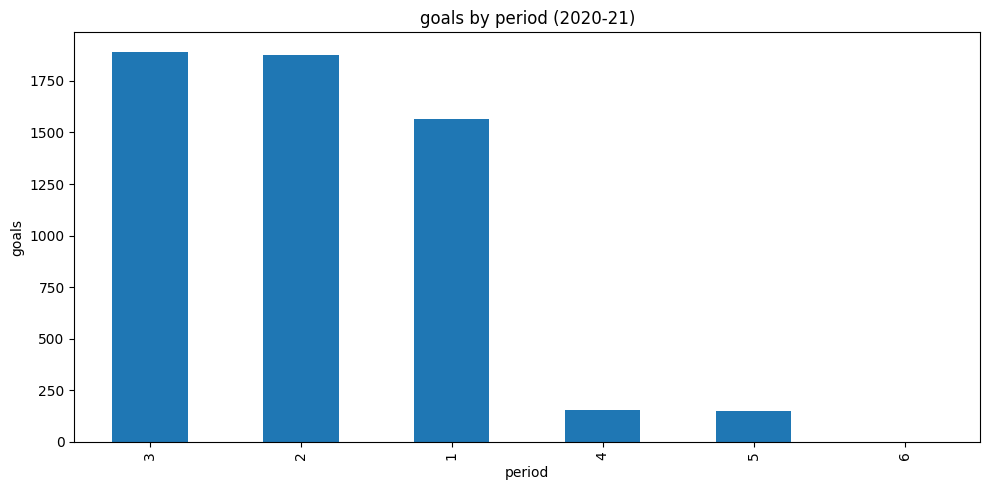

        shots  goals
period              
3       17970   1891
2       19835   1878
1       18496   1565
4         996    152
5         431    149
6           6      1 

20.0 

Caught: unknown team 'Montreal', choose from ['ANA', 'ARI', 'BOS', 'BUF', 'CAR', 'CBJ', 'CGY', 'CHI', 'COL', 'DAL', 'DET', 'EDM', 'FLA', 'LAK', 'MIN', 'MTL', 'NJD', 'NSH', 'NYI', 'NYR', 'OTT', 'PHI', 'PIT', 'SJS', 'STL', 'TBL', 'TOR', 'VAN', 'VGK', 'WPG', 'WSH']


In [21]:
tests = [
    # wrist-shot goal % for MTL vs TOR
    {"season": 2020, "metric": "goal_pct", "group_by": "team",
     "filters": [{"column": "team", "op": "in", "value": ["MTL", "TOR"]},
                 {"column": "shot_type", "op": "==", "value": "wrist"}]},

    # goals per period, plotted
    {"season": 2020, "metric": "goals", "group_by": "period", "plot": True},

    # % of Toronto's goals scored on the power play
    {"season": 2020, "metric": "percentage",
     "filters": [{"column": "team", "op": "==", "value": "TOR"},
                 {"column": "event_type", "op": "==", "value": "goal"}],
     "percent_of": {"column": "strength_type", "op": "==", "value": "Power play"}},
]

for args in tests:
    validate(args)
    print(query(**args), "\n")

# should be rejected
bad = {"season": 2020, "metric": "goals",
       "filters": [{"column": "team", "op": "==", "value": "Montreal"}]}
try:
    validate(bad)
except ValueError as e:
    print("Caught:", e)

## System prompt for Qwen

In [41]:
EXAMPLES_TEXT = """
EXAMPLES:
1. QUESTION: "How many power-play goals did Edmonton score in 2020-21?"
   YOUR REPLY: {"season": 2020, "metric": "goals", "filters": [{"column": "team", "op": "==", "value": "EDM"}, {"column": "strength_type", "op": "==", "value": "Power play"}]}

2. QUESTION: "Which teams had the best goal percentage in the 2020-21 playoffs?"
   YOUR REPLY: {"season": 2020, "metric": "goal_pct", "group_by": "team", "filters": [{"column": "game_type", "op": "==", "value": "Playoffs"}]}

3. QUESTION: "What share of Boston's shots were snap shots in 2020-21?"
   YOUR REPLY: {"season": 2020, "metric": "percentage", "filters": [{"column": "team", "op": "==", "value": "BOS"}], "percent_of": {"column": "shot_type", "op": "==", "value": "snap"}}

4. QUESTION: "Show a chart of shots by strength type for 2020-21"
   YOUR REPLY: {"season": 2020, "metric": "shots", "group_by": "strength_type", "plot": true}

5. QUESTION: "Who had the most hits in 2020-21?"
   YOUR REPLY: {"cannot_answer": "hits are not tracked, only shots on goal and goals"}
"""

sys_prompt = f"""You are an LLM tool caller that help answer questions about NHL shots
and goals by calling tools that query a table
You don't answer directly. Instead, you write a JSON query that is run by code.
YOUR REPLY SHOULD ONLY BE THE JSON AND NOTHING ELSE.

The data has one row per shot on goal, and goals count as shots too.
We only have these seasons: {cached_seasons()} (2020 means the 2020-21 season).


The JSON CAN ONLY  HAVE these KEYS:
  season      the start year of the season, like 2020
  metric      what to compute: {METRICS}
              -shots and goals are counts, goal_pct is 100 * goals / shots,
              -percentage is the % of rows that match percent_of
  filters     optional list of conditions each one given by  [{{"column": ..., "op": ..., "value": ...}},]
  group_by    optional, to get one result per group: {GROUP_BY}
  percent_of  one condition, only used when metric is "percentage"
  plot        true only if the user asks for a plot, chart or graph (needs group_by)
  plot_type   optional, one of {PLOT_TYPES}, "bar" by default

Values you can use in filters:
  team           {TEAMS}
                 these are the usual NHL abbreviations (Boston is BOS, Vegas is VGK, ...)
  shot_type      {SHOT_TYPES}
  game_type      {GAME_TYPES}
  event_type     {EVENT_TYPES}
  strength_type  {STRENGTH_TYPES}
  op             {OPERATORS}  ("in" and "not in" take a list)

period can only be used in group_by. Periods 4 and above are overtime.

If the question can't be answered with this data, reply {{"cannot_answer": "why"}}.
Don't make up numbers.

EXAMPLES:

""" + EXAMPLES_TEXT

## Load the model

The first run downloads ~8 GB of weights to the Hugging Face cache.

In [26]:
from ift6758.llm import load_model

model, tokenizer = load_model()
print(f"Loaded on {model.device} ({model.dtype})")

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Loaded on cuda:0 (torch.float16)


In [27]:
#test if model interface works
messages = [{"role": "user", "content": "In one sentence, what is a hat trick in hockey?"}]
inputs = tokenizer.apply_chat_template(
    messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
).to(model.device)
output_ids = model.generate(**inputs, max_new_tokens=64)
print(tokenizer.decode(output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))

In hockey, a hat trick occurs when a player scores a goal, assists on two goals, or records a goal and two assists in the same game.


## QUERY interface

In [46]:
from ift6758.llm.qwen import ask_qwen

def parse_reply(reply):
    # looks for JSON object
    match = re.search(r"\{.*\}", reply, re.DOTALL)
    if match is None:
        raise ValueError("no JSON found, reply with one JSON object only")
    return json.loads(match.group())


def check_reply(reply):
    # raises an error if anything is wrong
    args = parse_reply(reply)
    if "cannot_answer" in args:
        return "Cannot answer: " + args["cannot_answer"]
    validate(args)
    return query(**args)


def ask(question, tries=3):
    prompt = question
    for attempt in range(tries):
        reply = ask_qwen(model, tokenizer, prompt,system=sys_prompt, max_new_tokens=300)
        print(f"attempt {attempt + 1}: {reply}")
        try:
            return check_reply(reply), attempt
        except (ValueError, KeyError, TypeError) as e:
            print(f"  failed: {e}")
            prompt = f"{question}\n\nYour reply was: {reply}\nIt failed: {e}\nReply with the JSON only."
    return None, tries - 1

Test

In [47]:
result, retries = ask("How many shots did Calgary take in the 2020-21 regular season?")
print(result, retries)

[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


attempt 1: {"season": 2020, "metric": "shots", "filters": [{"column": "team", "op": "==", "value": "CGY"}], "group_by": ["game_type"]}
                shots  goals
game_type                   
Regular season   1694    158 0


# Evaluation questions
Here we manually calculate the answers to the questions and use them as reference

In [48]:
# 8 evaluation questions
QUESTIONS = [
    "How many goals did Montreal score in the 2020-21 regular season?",
    "How many slap shots were taken in the 2020-21 playoffs?",
    "Which team took the most shots in 2020-21?",
    "What was the goal percentage for each shot type in 2020-21?",
    "Compare wrist-shot goal percentages for Montréal and Toronto in 2020-21",
    "What was the goal percentage on backhand shots in the 2020-21 playoffs?",
    "Plot the number of goals per period in 2020-21",
    "Which player made the most passes in 2020-21?",
]

# reference answers, computed by hand with pandas
regular = df[df["game_type"] == "Regular season"]
playoffs = df[df["game_type"] == "Playoffs"]

# Q1: Montreal goals in the regular season
mtl = regular[regular["team"] == "MTL"]
q1 = int(mtl["is_goal"].sum())

# Q2: slap shots in the playoffs
slaps = playoffs[playoffs["shot_type"] == "slap"]
q2 = len(slaps)

# Q3: team with the most shots
shots_per_team = df["team"].value_counts()
q3 = shots_per_team.idxmax()

# Q4: goal % for each shot type
q4 = df.groupby("shot_type")["is_goal"].mean() * 100
q4 = q4.round(2).rename("goal_pct")

# Q5: wrist-shot goal % for MTL and TOR
wrist = df[(df["shot_type"] == "wrist") & (df["team"].isin(["MTL", "TOR"]))]
q5 = wrist.groupby("team")["is_goal"].mean() * 100
q5 = q5.round(2).rename("goal_pct")

# Q6: goal % on backhands in the playoffs
backhand = playoffs[playoffs["shot_type"] == "backhand"]
q6 = round(backhand["is_goal"].mean() * 100, 2)

# Q7: goals per period (for the plot)
q7 = df.groupby("period")["is_goal"].sum().rename("goals")

# Q8: passes are not in the data, so the system should refuse
q8 = "CANNOT_ANSWER"

REFERENCES = [q1, q2, q3, q4, q5, q6, q7, q8]

for i in range(len(QUESTIONS)):
    print(f"Q{i + 1}: {QUESTIONS[i]}")
    print(REFERENCES[i], "\n")

Q1: How many goals did Montreal score in the 2020-21 regular season?
161 

Q2: How many slap shots were taken in the 2020-21 playoffs?
704 

Q3: Which team took the most shots in 2020-21?
VGK 

Q4: What was the goal percentage for each shot type in 2020-21?
shot_type
backhand       12.08
deflected      15.58
slap            7.03
snap           10.41
tip-in         18.01
wrap-around     6.80
wrist           9.09
Name: goal_pct, dtype: float64 

Q5: Compare wrist-shot goal percentages for Montréal and Toronto in 2020-21
team
MTL     8.59
TOR    10.37
Name: goal_pct, dtype: float64 

Q6: What was the goal percentage on backhand shots in the 2020-21 playoffs?
10.02 

Q7: Plot the number of goals per period in 2020-21
period
1    1565
2    1878
3    1891
4     152
5     149
6       1
Name: goals, dtype: int64 

Q8: Which player made the most passes in 2020-21?
CANNOT_ANSWER 



# Generation of our answers using qwen against the 8 reference questions

[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



*************** Q1: How many goals did Montreal score in the 2020-21 regular season?


[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


attempt 1: {"season": 2020, "metric": "goals", "filters": [{"column": "team", "op": "==", "value": "MTL"}, {"column": "game_type", "op": "==", "value": "Regular season"}]}
result:
161
reference:
161

*************** Q2: How many slap shots were taken in the 2020-21 playoffs?


[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

attempt 1: {"season": 2020, "metric": "goal_pct", "group_by": ["team"], "filters": [{"column": "shot_type", "op": "==", "value": "wrist"}, {"column": "team", "op": "in", "value": ["MTL", "TOR"]}]}
  failed: Grouper for '<class 'pandas.core.frame.DataFrame'>' not 1-dimensional


[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


attempt 2: {"season": 2020, "metric": "goal_pct", "group_by": "team", "filters": [{"column": "shot_type", "op": "==", "value": "wrist"}, {"column": "team", "op": "in", "value": ["MTL", "TOR"]}]}
result:
team
TOR    10.37
MTL     8.59
Name: event_type, dtype: float64
reference:
team
MTL     8.59
TOR    10.37
Name: goal_pct, dtype: float64

*************** Q6: What was the goal percentage on backhand shots in the 2020-21 playoffs?


[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


attempt 1: {"season": 2020, "metric": "goal_pct", "filters": [{"column": "shot_type", "op": "==", "value": "backhand"}, {"column": "game_type", "op": "==", "value": "Playoffs"}]}
result:
10.02
reference:
10.02

*************** Q7: Plot the number of goals per period in 2020-21
attempt 1: {"season": 2020, "metric": "goals", "group_by": "period", "plot": true}


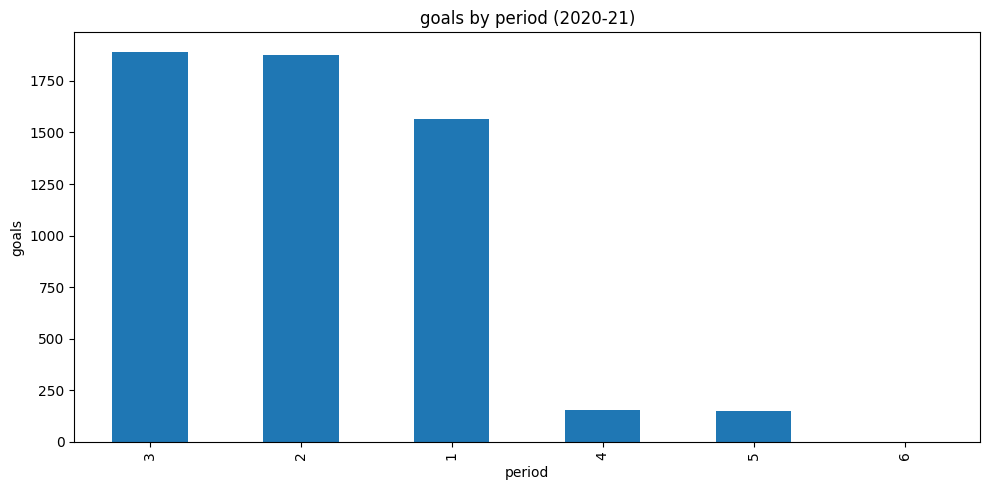

[transformers] Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


result:
        shots  goals
period              
3       17970   1891
2       19835   1878
1       18496   1565
4         996    152
5         431    149
6           6      1
reference:
period
1    1565
2    1878
3    1891
4     152
5     149
6       1
Name: goals, dtype: int64

*************** Q8: Which player made the most passes in 2020-21?
attempt 1: {"cannot_answer": "passes are not tracked in the available data"}
result:
Cannot answer: passes are not tracked in the available data
reference:
CANNOT_ANSWER


,num,question,first attempt executed,retries
0,1,How many goals did Montreal score in the 2020-...,Yes,0
1,2,How many slap shots were taken in the 2020-21 ...,Yes,0
2,3,Which team took the most shots in 2020-21?,Yes,0
3,4,What was the goal percentage for each shot typ...,Yes,0
4,5,Compare wrist-shot goal percentages for Montré...,No,1
5,6,What was the goal percentage on backhand shots...,Yes,0
6,7,Plot the number of goals per period in 2020-21,Yes,0
7,8,Which player made the most passes in 2020-21?,Yes,0


In [49]:
rows = []
for i in range(len(QUESTIONS)):
    question = QUESTIONS[i]

    print(f"\n*************** Q{i + 1}: {question}")
    result, retries = ask(question)

    print("result:")
    print(result)
    print("reference:")
    print(REFERENCES[i])

    rows.append({
        "num": i + 1,
        "question": question,
        "first attempt executed": "Yes" if retries == 0 and result is not None else "No",
        "retries": retries,
    })

results = pd.DataFrame(rows)
results